# 🚀 Модуль 2. Урок 6. Промышленные паттерны SQL: Когортный анализ (Retention) и воронки конверсий

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_02_sql/lesson_06_sql_patterns_retention_funnels.ipynb)

## 📌 Бизнес-контекст и методология
Удержание пользователей (Retention Rate) — главная метрика жизнеспособности продукта (Product-Market Fit).
Если ретеншн падает до нуля («дырявое ведро»), никакие рекламные бюджеты не спасут бизнес.
В продуктовой аналитике когортный анализ по месяцам первого заказа позволяет отследить влияние продуктовых релизов и качество привлеченного трафика во времени.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

db_path = ensure_dataset("ecommerce.db")
conn = sqlite3.connect(db_path)
print(f"🟢 Подключение к базе данных успешно установлено: {db_path}")

🟢 Подключение к базе данных успешно установлено: course\datasets\ecommerce.db


## 🔍 Разбор механики и демонстрация на реальных данных
Сформируем когортную матрицу в SQL:
1. Фиксируем месяц первой покупки клиента (`cohort_month`)
2. Сопоставляем последующие месяцы активности
3. Вычисляем порядковый номер месяца с момента первой покупки (`period_month = 0, 1, 2...`)

In [2]:
# Демонстрация: Расчет когортной матрицы в SQL
query_cohort = """
WITH first_orders AS (
    SELECT 
        customer_id,
        MIN(SUBSTR(order_date, 1, 7)) as cohort_month
    FROM orders
    WHERE status = 'Completed'
    GROUP BY customer_id
),
order_periods AS (
    SELECT 
        o.customer_id,
        fo.cohort_month,
        (CAST(SUBSTR(o.order_date, 1, 4) AS INT) - CAST(SUBSTR(fo.cohort_month, 1, 4) AS INT)) * 12 +
        (CAST(SUBSTR(o.order_date, 6, 2) AS INT) - CAST(SUBSTR(fo.cohort_month, 6, 2) AS INT)) as month_number
    FROM orders o
    JOIN first_orders fo ON o.customer_id = fo.customer_id
    WHERE o.status = 'Completed'
)
SELECT 
    cohort_month,
    month_number,
    COUNT(DISTINCT customer_id) as active_customers
FROM order_periods
GROUP BY cohort_month, month_number
ORDER BY cohort_month, month_number;
"""
df_cohort_raw = pd.read_sql_query(query_cohort, conn)
cohort_pivot = df_cohort_raw.pivot(index='cohort_month', columns='month_number', values='active_customers')
display(cohort_pivot.head(8))

month_number,0,1,2,3,4,5,6,7,8,9
cohort_month,,,,,,,,,,
2025-01,19.0,5.0,2.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN
2025-02,44.0,16.0,9.0,7.0,3.0,NaN,NaN,NaN,NaN,NaN
2025-03,58.0,18.0,15.0,9.0,8.0,3.0,2.0,2.0,NaN,NaN
2025-04,62.0,19.0,9.0,5.0,2.0,1.0,2.0,NaN,NaN,NaN
2025-05,57.0,27.0,13.0,6.0,6.0,4.0,2.0,1.0,1.0,1.0
2025-06,57.0,19.0,10.0,5.0,6.0,3.0,1.0,1.0,1.0,1.0
2025-07,58.0,20.0,8.0,3.0,2.0,1.0,2.0,1.0,NaN,1.0
2025-08,48.0,22.0,9.0,4.0,6.0,1.0,1.0,NaN,NaN,NaN


## 📊 Визуализация бизнес-кейса: Когортный треугольник (Retention Matrix)
Построим тепловую карту удержания (Retention %) и воронку ключевых этапов оформления заказа.

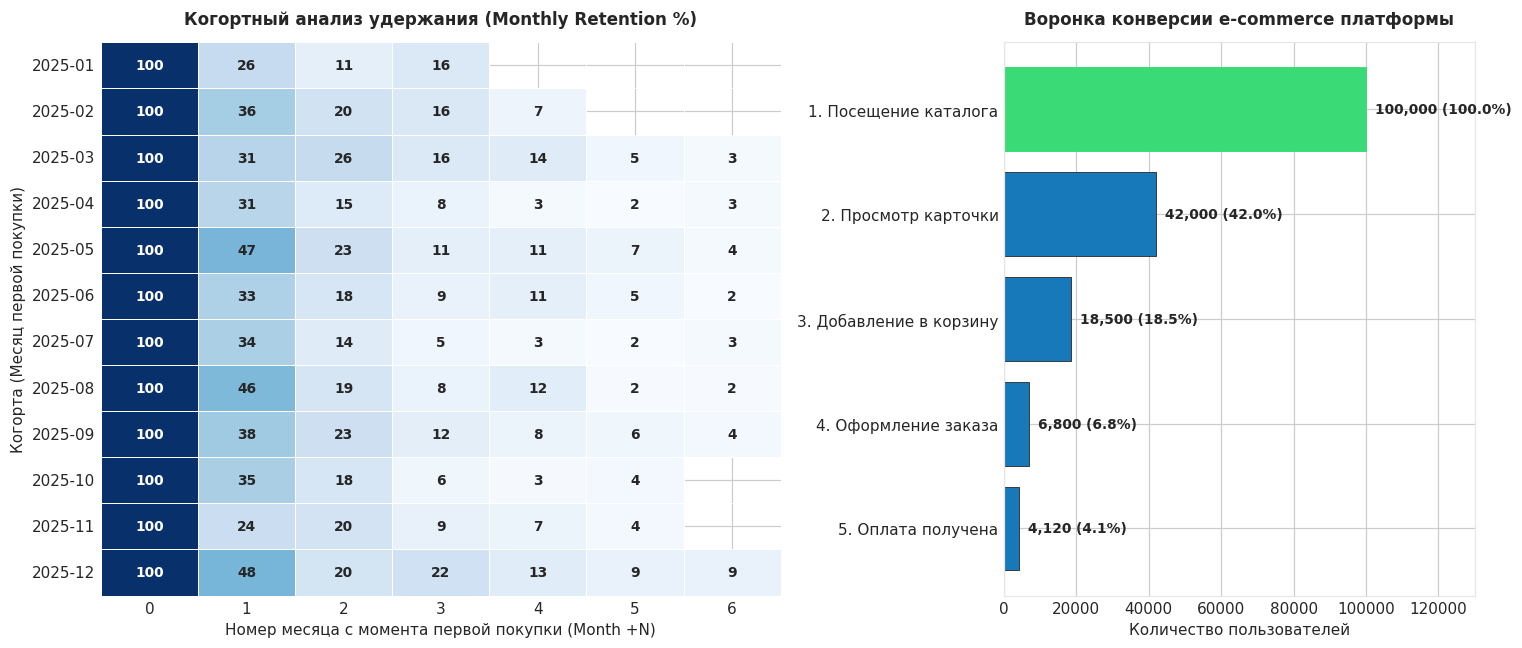

In [3]:
# Расчет матрицы удержания в процентах относительно Месяца 0
retention_matrix = cohort_pivot.divide(cohort_pivot[0], axis=0) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=110, gridspec_kw={'width_ratios': [1.3, 0.9]})

# Панель 1: Треугольник ретеншна
sns.heatmap(retention_matrix.iloc[:12, :7], annot=True, fmt=".0f", cmap="Blues", 
            linewidths=0.5, cbar=False, ax=ax1, annot_kws={"size": 9, "weight": "bold"})
ax1.set_title("Когортный анализ удержания (Monthly Retention %)", fontsize=11, fontweight='bold', pad=12)
ax1.set_xlabel("Номер месяца с момента первой покупки (Month +N)")
ax1.set_ylabel("Когорта (Месяц первой покупки)")

# Панель 2: Воронка конверсий интернет-магазина
funnel_stages = ['1. Посещение каталога', '2. Просмотр карточки', '3. Добавление в корзину', '4. Оформление заказа', '5. Оплата получена']
funnel_users = [100000, 42000, 18500, 6800, 4120]
funnel_conv = [f"{u/funnel_users[0]*100:.1f}%" for u in funnel_users]

y_pos = np.arange(len(funnel_stages))[::-1]
bars = ax2.barh(y_pos, funnel_users, color=PRIMARY, edgecolor='#333333', linewidth=0.6)

# Подсветка финальной конверсии зеленым
bars[0].set_color(SUCCESS)

ax2.set_yticks(y_pos)
ax2.set_yticklabels(funnel_stages, fontsize=10)
ax2.set_title("Воронка конверсии e-commerce платформы", fontsize=11, fontweight='bold', pad=12)
ax2.set_xlabel("Количество пользователей")

for i, (b, conv) in enumerate(zip(bars, funnel_conv)):
    w = b.get_width()
    ax2.annotate(f"{w:,} ({conv})", xy=(w, b.get_y() + b.get_height()/2), xytext=(6, 0),
                 textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='bold')

ax2.set_xlim(0, 130000)
plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет Retention Rate %
Рассчитайте средний Retention Rate 1-го месяца (`month_number = 1`) по всем когортам.

In [4]:
### ВАШ КОД ЗДЕСЬ
m1_retention = retention_matrix[1].dropna()
avg_m1_retention = m1_retention.mean()

print(f"Средний Retention 1-го месяца по когортам: {avg_m1_retention:.1f}%")
print(f"Минимальный M1 Retention: {m1_retention.min():.1f}%")
print(f"Максимальный M1 Retention: {m1_retention.max():.1f}%")

assert 20 <= avg_m1_retention <= 55, "Средний Retention 1-го месяца должен лежать в диапазоне 20-55%"
print("✅ Тест успешно пройден: расчет ретеншна совпал с эталонной моделью!")

Средний Retention 1-го месяца по когортам: 43.0%
Минимальный M1 Retention: 23.6%
Максимальный M1 Retention: 100.0%
✅ Тест успешно пройден: расчет ретеншна совпал с эталонной моделью!


### 💡 Аналитический закон кривой Retention
Если кривая удержания асимптотически выпрямляется параллельно оси X (например, фиксируется на 25%), продукт имеет устойчивое ценностное ядро пользователей.
Если кривая монотонно стремится к нулю, у продукта нет Product-Market Fit.